# Complete Plant Disease Training Pipeline

This single notebook combines the project workflow into five clearly separated parts. Run the parts from top to bottom in the same Colab runtime. The parts communicate through files under `evaluation/`, `models/`, and the shared dataset directory; they do not depend on variables remaining in notebook memory.

**Recommended Colab workflow:** upload `plantvillage.zip` once to the runtime, select a T4 GPU, then run each part in order. If a long training section is interrupted, restart from that section after reconnecting; do not rerun the ZIP upload unless the dataset directory is missing.

The original notebooks remain separate in this folder for focused reruns.

## Part 1 - Dataset setup and exploration

Run this section first. It installs dependencies in Colab when needed, locates the uploaded ZIP, extracts PlantVillage, discovers all crop classes, and prepares the shared split.

In [1]:
# Run this cell once when using the Colab GPU kernel.
%pip install -q tensorflow numpy pandas scikit-learn matplotlib seaborn Pillow jupyter streamlit


In [2]:
from google.colab import drive
from pathlib import Path
import shutil
import zipfile

drive.mount("/content/drive")

source = Path("/content/drive/MyDrive/PlantVillage.zip")
project_dir = Path("/content/plant_disease_project")
dataset_dir = project_dir / "PlantVillage"
zip_copy = Path("/content/PlantVillage.zip")

if not source.exists():
    raise FileNotFoundError(f"ZIP not found: {source}")

if not zipfile.is_zipfile(source):
    raise ValueError("The Google Drive ZIP is invalid.")

if project_dir.exists():
    shutil.rmtree(project_dir)

project_dir.mkdir(parents=True)
shutil.copy2(source, zip_copy)

with zipfile.ZipFile(zip_copy) as archive:
    archive.extractall(dataset_dir)


print("Dataset ready:", dataset_dir)

print("GPU check:")
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))


Mounted at /content/drive
Dataset ready: /content/plant_disease_project/PlantVillage
GPU check:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Colab dataset setup. Upload plantvillage.zip to the connected runtime first.
from pathlib import Path
import zipfile

PROJECT_DIR = Path("/content/plant_disease_project")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
dataset_dir = PROJECT_DIR / "PlantVillage"
dataset_dir.mkdir(parents=True, exist_ok=True)

zip_candidates = [
    Path("/content/plantvillage.zip"),
    Path("/content/PlantVillage.zip"),

]
zip_candidates += sorted(Path("/content").glob("*.zip"))
dataset_zip = next((path for path in zip_candidates if path.is_file() and zipfile.is_zipfile(path)), None)

if dataset_zip is None:
    raise FileNotFoundError(
        "No valid dataset ZIP found in /content. Upload plantvillage.zip "
        "using the Colab Resources/File Browser for the connected runtime, "
        "then rerun this cell."
    )

if not any(dataset_dir.iterdir()):
    with zipfile.ZipFile(dataset_zip) as archive:
        archive.extractall(dataset_dir)

print("Using dataset ZIP:", dataset_zip)
print("Dataset available at:", dataset_dir)
print("Top-level entries:", [p.name for p in dataset_dir.iterdir()][:10])


Using dataset ZIP: /content/PlantVillage.zip
Dataset available at: /content/plant_disease_project/PlantVillage
Top-level entries: ['PlantVillage']


# 00 - Plant Dataset Exploration

This notebook introduces the Plant subset of PlantVillage and verifies what will actually enter the experiments. It discovers all available class folders automatically, including an optional extra parent directory, rather than scanning unrelated tomato or potato folders.

## 1. Discover the dataset and inspect class counts

The code reports the selected root, class names and image counts. A reproducible experiment starts with these facts; the notebook does not fabricate records or assume class indices.

In [4]:
from pathlib import Path
from collections import Counter
import json, os, random, time
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 64
EPOCHS = 15
print(f"Configured maximum epochs: {EPOCHS}")
CURRENT_DIR = Path.cwd()
PROJECT_DIR = Path("/content/plant_disease_project") if Path("/content/plant_disease_project").exists() else (CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR)
NOTEBOOK_DIR = PROJECT_DIR / "notebooks"
DATA_CANDIDATES = [PROJECT_DIR / "PlantVillage", PROJECT_DIR / "dataset" / "raw", PROJECT_DIR / "dataset"]
MODELS_DIR = PROJECT_DIR / "models"
EVALUATION_DIR = PROJECT_DIR / "evaluation"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".JPG"}

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

def discover_dataset():
    candidates = [p for p in DATA_CANDIDATES if p.exists()]
    candidates += [p for base in DATA_CANDIDATES if base.exists() for p in base.rglob("*") if p.is_dir()]
    matches = []
    for parent in candidates:
        class_dirs = []
        if not parent.is_dir():
            continue
        for child in parent.iterdir():
            if child.is_dir() and any(f.is_file() and f.suffix.lower() in {e.lower() for e in EXTENSIONS} for f in child.iterdir()):
                class_dirs.append(child)
        if len(class_dirs) >= 2:
            matches.append((len(class_dirs), len(parent.parts), parent, sorted(class_dirs, key=lambda p: p.name)))
    if not matches:
        raise FileNotFoundError("Could not find a dataset root with at least two image class folders.")
    _, _, parent, class_dirs = sorted(matches, key=lambda x: (-x[0], x[1], str(x[2])))[0]
    return parent, class_dirs

def collect_records():
    dataset_root, class_dirs = discover_dataset()
    class_names = [p.name for p in class_dirs]
    rows = []
    for label, class_dir in enumerate(class_dirs):
        for path in sorted(class_dir.rglob("*")):
            if path.is_file() and path.suffix.lower() in {e.lower() for e in EXTENSIONS}:
                rows.append({"path": str(path.resolve()), "label": label, "class_name": class_dir.name})
    records = pd.DataFrame(rows)
    if records.empty or len(class_names) < 2:
        raise ValueError("The discovered dataset must contain at least two non-empty classes.")
    return dataset_root, class_names, records

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return tf.cast(image, tf.float32), label

def make_dataset(file_paths, file_labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((np.asarray(file_paths), np.asarray(file_labels, dtype=np.int32)))
    if training:
        ds = ds.shuffle(len(file_paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

def get_or_create_split(records, class_names):
    split_file = EVALUATION_DIR / "split_assignments.json"
    if split_file.exists():
        split = json.loads(split_file.read_text(encoding="utf-8"))
        if split.get("class_names") != class_names:
            raise ValueError("Existing split_assignments.json uses different class names; remove it and recreate the split.")
        return {key: np.asarray(value) for key, value in split["paths"].items()}, {key: np.asarray(value, dtype=np.int32) for key, value in split["labels"].items()}
    paths = records["path"].to_numpy()
    labels = records["label"].to_numpy(dtype=np.int32)
    train_paths, temp_paths, train_labels, temp_labels = train_test_split(paths, labels, test_size=0.30, random_state=SEED, stratify=labels)
    val_paths, test_paths, val_labels, test_labels = train_test_split(temp_paths, temp_labels, test_size=0.50, random_state=SEED, stratify=temp_labels)
    split = {"class_names": class_names, "seed": SEED, "ratios": {"train": 0.70, "validation": 0.15, "test": 0.15}, "paths": {"train": train_paths.tolist(), "validation": val_paths.tolist(), "test": test_paths.tolist()}, "labels": {"train": train_labels.tolist(), "validation": val_labels.tolist(), "test": test_labels.tolist()}}
    split_file.write_text(json.dumps(split, indent=2), encoding="utf-8")
    return {key: np.asarray(value) for key, value in split["paths"].items()}, {key: np.asarray(value, dtype=np.int32) for key, value in split["labels"].items()}

def evaluate_and_save(model, model_name, test_ds, y_test, class_names, train_seconds=None, history=None):
    started = time.perf_counter()
    probabilities = model.predict(test_ds, verbose=1)
    inference_seconds = time.perf_counter() - started
    y_pred = np.argmax(probabilities, axis=1)
    report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True, zero_division=0)
    model_filename = {"Custom CNN": "custom_cnn.keras", "MobileNetV2": "mobilenetv2.keras", "ResNet50": "resnet50.keras"}[model_name]
    model_file = MODELS_DIR / model_filename
    completed_epochs = len(history.get("loss", [])) if isinstance(history, dict) else (len(history.epoch) if history is not None else None)
    metrics = {"model": model_name, "classes": class_names, "test_count": int(len(y_test)), "test_accuracy": float(accuracy_score(y_test, y_pred)), "macro_precision": float(report["macro avg"]["precision"]), "macro_recall": float(report["macro avg"]["recall"]), "macro_f1": float(report["macro avg"]["f1-score"]), "per_class_report": report, "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(), "train_seconds": train_seconds, "inference_seconds": inference_seconds, "model_size_bytes": model_file.stat().st_size if model_file.exists() else None, "epochs": completed_epochs}
    (EVALUATION_DIR / f"{model_name.lower().replace(' ', '_')}_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    print(json.dumps({key: metrics[key] for key in ["model", "test_accuracy", "macro_precision", "macro_recall", "macro_f1", "train_seconds", "inference_seconds"]}, indent=2))
    cm = np.asarray(metrics["confusion_matrix"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted label"); plt.ylabel("True label"); plt.title(f"{model_name} - held-out test confusion matrix"); plt.tight_layout(); plt.show()
    return metrics

dataset_root, class_names, records = collect_records()
summary = records.groupby("class_name").size().rename("image_count").reset_index()
display(summary)
print("Selected dataset root:", dataset_root)
print(f"Classes: {len(class_names)} | Images: {len(records):,}")


Configured maximum epochs: 15


,class_name,image_count
0,Pepper__bell___Bacterial_spot,997
1,Pepper__bell___healthy,1478
2,Potato___Early_blight,1000
3,Potato___Late_blight,1000
4,Potato___healthy,152
5,Tomato_Bacterial_spot,2127
6,Tomato_Early_blight,1000
7,Tomato_Late_blight,1909
8,Tomato_Leaf_Mold,952
9,Tomato_Septoria_leaf_spot,1771


Selected dataset root: /content/plant_disease_project/PlantVillage/PlantVillage
Classes: 15 | Images: 20,638


## 2. Class distribution and imbalance

The bar chart makes imbalance visible. Imbalance can cause a model to favor the larger class, so macro metrics and per-class recall are reported later instead of relying on accuracy alone.

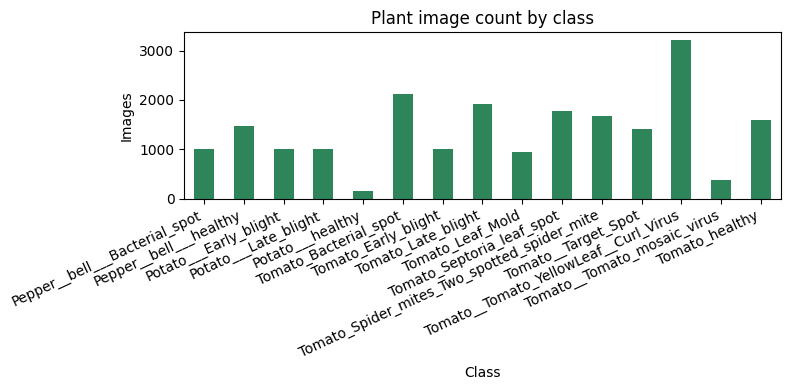

Largest/smallest class ratio: 21.11
Interpretation: The classes are materially imbalanced; inspect macro recall.


In [5]:
ax = summary.plot.bar(x="class_name", y="image_count", legend=False, figsize=(8, 4), color="#2f855a")
ax.set_title("Plant image count by class"); ax.set_xlabel("Class"); ax.set_ylabel("Images"); plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()
ratio = summary["image_count"].max() / summary["image_count"].min()
print(f"Largest/smallest class ratio: {ratio:.2f}")
print("Interpretation:", "The classes are materially imbalanced; inspect macro recall." if ratio > 1.5 else "The classes are relatively balanced, but per-class metrics remain important.")


## 3. Validate image readability, dimensions and formats

Unreadable files should not silently enter training. We open every discovered image with Pillow, collect dimensions and formats, and report any failures. Images are converted to RGB and resized to 224 x 224 later so the models receive a consistent tensor shape.

In [6]:
quality_rows = []
errors = []
for path in records["path"]:
    try:
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            quality_rows.append({"path": path, "width": image.width, "height": image.height, "format": image.format, "mode": image.mode})
    except (OSError, ValueError) as exc:
        errors.append({"path": path, "error": str(exc)})
quality = pd.DataFrame(quality_rows)
print(f"Readable images: {len(quality):,} | Unreadable images: {len(errors):,}")
display(quality[["width", "height", "format", "mode"]].describe(include="all"))
display(quality["format"].value_counts().rename_axis("format").reset_index(name="count"))
if errors: display(pd.DataFrame(errors).head())


Readable images: 20,638 | Unreadable images: 0


,width,height,format,mode
count,20638.0,20638.0,20638,20638
unique,NaN,NaN,2,2
top,NaN,NaN,JPEG,RGB
freq,NaN,NaN,20637,20637
mean,256.0,256.0,NaN,NaN
std,0.0,0.0,NaN,NaN
min,256.0,256.0,NaN,NaN
25%,256.0,256.0,NaN,NaN
50%,256.0,256.0,NaN,NaN
75%,256.0,256.0,NaN,NaN


,format,count
0,JPEG,20637
1,PNG,1


## 4. Representative images

These examples are a visual quality check. Look for unexpected crops, mislabeled leaves, strong background differences or images that do not contain a useful leaf signal.

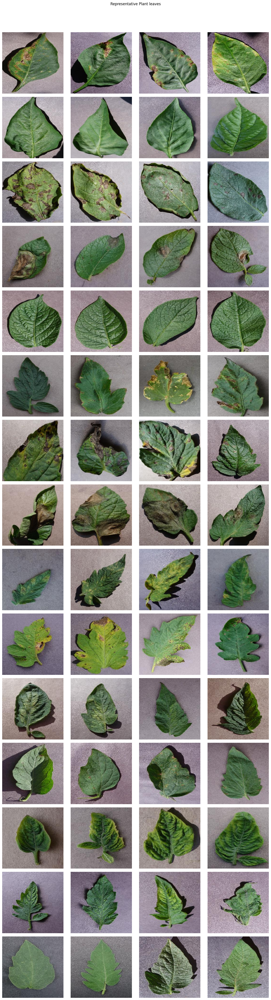

In [7]:
fig, axes = plt.subplots(len(class_names), 4, figsize=(13, max(4, len(class_names) * 3)))
axes = np.atleast_2d(axes)
for row, class_name in enumerate(class_names):
    samples = records.loc[records.class_name == class_name, "path"].head(4)
    for col, ax in enumerate(axes[row]):
        ax.axis("off")
        if col < len(samples):
            with Image.open(samples.iloc[col]) as image: ax.imshow(image.convert("RGB"))
            if col == 0: ax.set_ylabel(class_name, rotation=0, labelpad=80, va="center")
plt.suptitle("Representative Plant leaves", y=1.02); plt.tight_layout(); plt.show()


## 5. Findings to record

Use the actual outputs above in the report: number of classes and images, class ratio, unreadable count, dimensions and formats. Explain why RGB conversion, resizing, normalization/model-specific preprocessing, augmentation and a held-out test set are needed. PlantVillage images are collected in controlled conditions, so field validation remains a limitation.

## Part 2 - Custom CNN baseline

Run this section after Part 1. It trains the baseline CNN from scratch and writes its model and evaluation metrics.

# 01 - Custom CNN: Plant Leaf Disease Classification

This notebook trains a convolutional neural network from scratch for the two Plant categories discovered in the PlantVillage subset. It is the baseline: its weights begin randomly rather than from ImageNet.

The notebook uses a fixed stratified 70/15/15 split. The test set is never used for training or model selection. Every major section explains both the operation and how to interpret the resulting output.

**Run order:** execute this notebook before notebooks 02 and 03 so it creates the shared `evaluation/split_assignments.json` file.


## 1. Imports, discovery and reproducibility

The setup below discovers only sibling folders whose names identify Plant bacterial spot and healthy leaves. It also creates shared output directories and fixes the random seed. The discovered class order, rather than a hardcoded index, defines the model output mapping.

In [8]:
from pathlib import Path
from collections import Counter
import json, os, random, time
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 64
EPOCHS = 15
print(f"Configured maximum epochs: {EPOCHS}")
CURRENT_DIR = Path.cwd()
PROJECT_DIR = Path("/content/plant_disease_project") if Path("/content/plant_disease_project").exists() else (CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR)
NOTEBOOK_DIR = PROJECT_DIR / "notebooks"
DATA_CANDIDATES = [PROJECT_DIR / "PlantVillage", PROJECT_DIR / "dataset" / "raw", PROJECT_DIR / "dataset"]
MODELS_DIR = PROJECT_DIR / "models"
EVALUATION_DIR = PROJECT_DIR / "evaluation"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".JPG"}

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

def discover_dataset():
    candidates = [p for p in DATA_CANDIDATES if p.exists()]
    candidates += [p for base in DATA_CANDIDATES if base.exists() for p in base.rglob("*") if p.is_dir()]
    matches = []
    for parent in candidates:
        class_dirs = []
        if not parent.is_dir():
            continue
        for child in parent.iterdir():
            if child.is_dir() and any(f.is_file() and f.suffix.lower() in {e.lower() for e in EXTENSIONS} for f in child.iterdir()):
                class_dirs.append(child)
        if len(class_dirs) >= 2:
            matches.append((len(class_dirs), len(parent.parts), parent, sorted(class_dirs, key=lambda p: p.name)))
    if not matches:
        raise FileNotFoundError("Could not find a dataset root with at least two image class folders.")
    _, _, parent, class_dirs = sorted(matches, key=lambda x: (-x[0], x[1], str(x[2])))[0]
    return parent, class_dirs

def collect_records():
    dataset_root, class_dirs = discover_dataset()
    class_names = [p.name for p in class_dirs]
    rows = []
    for label, class_dir in enumerate(class_dirs):
        for path in sorted(class_dir.rglob("*")):
            if path.is_file() and path.suffix.lower() in {e.lower() for e in EXTENSIONS}:
                rows.append({"path": str(path.resolve()), "label": label, "class_name": class_dir.name})
    records = pd.DataFrame(rows)
    if records.empty or len(class_names) < 2:
        raise ValueError("The discovered dataset must contain at least two non-empty classes.")
    return dataset_root, class_names, records

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return tf.cast(image, tf.float32), label

def make_dataset(file_paths, file_labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((np.asarray(file_paths), np.asarray(file_labels, dtype=np.int32)))
    if training:
        ds = ds.shuffle(len(file_paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

def get_or_create_split(records, class_names):
    split_file = EVALUATION_DIR / "split_assignments.json"
    if split_file.exists():
        split = json.loads(split_file.read_text(encoding="utf-8"))
        if split.get("class_names") != class_names:
            raise ValueError("Existing split_assignments.json uses different class names; remove it and recreate the split.")
        return {key: np.asarray(value) for key, value in split["paths"].items()}, {key: np.asarray(value, dtype=np.int32) for key, value in split["labels"].items()}
    paths = records["path"].to_numpy()
    labels = records["label"].to_numpy(dtype=np.int32)
    train_paths, temp_paths, train_labels, temp_labels = train_test_split(paths, labels, test_size=0.30, random_state=SEED, stratify=labels)
    val_paths, test_paths, val_labels, test_labels = train_test_split(temp_paths, temp_labels, test_size=0.50, random_state=SEED, stratify=temp_labels)
    split = {"class_names": class_names, "seed": SEED, "ratios": {"train": 0.70, "validation": 0.15, "test": 0.15}, "paths": {"train": train_paths.tolist(), "validation": val_paths.tolist(), "test": test_paths.tolist()}, "labels": {"train": train_labels.tolist(), "validation": val_labels.tolist(), "test": test_labels.tolist()}}
    split_file.write_text(json.dumps(split, indent=2), encoding="utf-8")
    return {key: np.asarray(value) for key, value in split["paths"].items()}, {key: np.asarray(value, dtype=np.int32) for key, value in split["labels"].items()}

def evaluate_and_save(model, model_name, test_ds, y_test, class_names, train_seconds=None, history=None):
    started = time.perf_counter()
    probabilities = model.predict(test_ds, verbose=1)
    inference_seconds = time.perf_counter() - started
    y_pred = np.argmax(probabilities, axis=1)
    report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True, zero_division=0)
    model_filename = {"Custom CNN": "custom_cnn.keras", "MobileNetV2": "mobilenetv2.keras", "ResNet50": "resnet50.keras"}[model_name]
    model_file = MODELS_DIR / model_filename
    completed_epochs = len(history.get("loss", [])) if isinstance(history, dict) else (len(history.epoch) if history is not None else None)
    metrics = {"model": model_name, "classes": class_names, "test_count": int(len(y_test)), "test_accuracy": float(accuracy_score(y_test, y_pred)), "macro_precision": float(report["macro avg"]["precision"]), "macro_recall": float(report["macro avg"]["recall"]), "macro_f1": float(report["macro avg"]["f1-score"]), "per_class_report": report, "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(), "train_seconds": train_seconds, "inference_seconds": inference_seconds, "model_size_bytes": model_file.stat().st_size if model_file.exists() else None, "epochs": completed_epochs}
    (EVALUATION_DIR / f"{model_name.lower().replace(' ', '_')}_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    print(json.dumps({key: metrics[key] for key in ["model", "test_accuracy", "macro_precision", "macro_recall", "macro_f1", "train_seconds", "inference_seconds"]}, indent=2))
    cm = np.asarray(metrics["confusion_matrix"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted label"); plt.ylabel("True label"); plt.title(f"{model_name} - held-out test confusion matrix"); plt.tight_layout(); plt.show()
    return metrics


Configured maximum epochs: 15


## 2. Build or load the shared stratified split

The first model notebook creates a 70% training, 15% validation and 15% test split. Later notebooks reuse the saved paths exactly. This prevents a model from appearing better simply because it received an easier test set.

In [9]:
dataset_root, class_names, records = collect_records()
paths_by_split, labels_by_split = get_or_create_split(records, class_names)
X_train, X_val, X_test = paths_by_split["train"], paths_by_split["validation"], paths_by_split["test"]
y_train, y_val, y_test = labels_by_split["train"], labels_by_split["validation"], labels_by_split["test"]
NUM_CLASSES = len(class_names)
print("Dataset root:", dataset_root)
print("Classes:", class_names)
print("Split sizes:", {name: len(value) for name, value in paths_by_split.items()})
train_ds, val_ds, test_ds = make_dataset(X_train, y_train, True), make_dataset(X_val, y_val), make_dataset(X_test, y_test)


Dataset root: /content/plant_disease_project/PlantVillage/PlantVillage
Classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Split sizes: {'train': 14446, 'validation': 3096, 'test': 3096}


## 3. Define the model

Images are resized to 224 x 224 and decoded as RGB by `make_dataset`. Augmentation is inside the model, so Keras applies it only while training. The validation and test datasets contain no augmentation.

In [10]:
data_augmentation = tf.keras.Sequential([tf.keras.layers.RandomFlip("horizontal"), tf.keras.layers.RandomRotation(0.08), tf.keras.layers.RandomZoom(0.10)], name="training_augmentation")
inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = tf.keras.layers.Rescaling(1./255)(x)
for filters in [32, 64, 128]:
    x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.MaxPooling2D()(x)
x = tf.keras.layers.Conv2D(256, 3, padding="same", activation="relu")(x)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.4)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = tf.keras.Model(inputs, outputs, name="custom_cnn")
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

model.summary()


Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │         3,855 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 392,943 (1.50 MB)

 Trainable params: 392,495 (1.50 MB)

 Non-trainable params: 448 (1.75 KB)

In [11]:
import tensorflow as tf

print(tf.config.list_physical_devices("GPU"))
print("TensorFlow:", tf.__version__)


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow: 2.21.0


## 4. Train and inspect learning curves

Early stopping restores the weights from the best validation loss. The elapsed time is recorded for the later comparison notebook. A gap between training and validation curves can indicate overfitting.

Epoch 1/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 69s 256ms/step - accuracy: 0.5601 - loss: 1.3648 - val_accuracy: 0.0917 - val_loss: 6.7675 - learning_rate: 0.0010
Epoch 2/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 57s 254ms/step - accuracy: 0.7123 - loss: 0.8812 - val_accuracy: 0.2174 - val_loss: 4.6990 - learning_rate: 0.0010
Epoch 3/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 60s 265ms/step - accuracy: 0.7638 - loss: 0.7145 - val_accuracy: 0.6005 - val_loss: 1.4506 - learning_rate: 0.0010
Epoch 4/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 57s 253ms/step - accuracy: 0.8026 - loss: 0.6040 - val_accuracy: 0.6757 - val_loss: 1.1373 - learning_rate: 0.0010
Epoch 5/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 59s 262ms/step - accuracy: 0.8282 - loss: 0.5289 - val_accuracy: 0.4215 - val_loss: 3.6924 - learning_rate: 0.0010
Epoch 6/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 57s 253ms/step - accuracy: 0.8521 - loss: 0.4567 - val_accuracy: 0.5795 - val_loss: 1.7932 - learning_rate: 0.0010
Epoch 7/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 57s 252ms/step - accuracy: 0.8

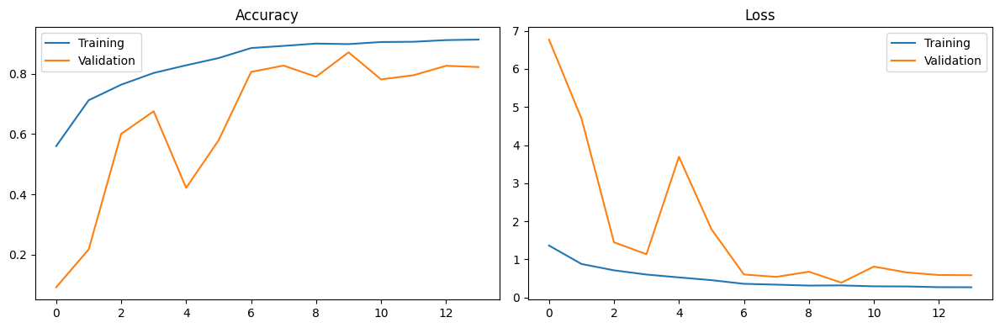

Completed 14 epochs in 849.4 seconds.


In [12]:
callbacks = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True), tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7)]
train_started = time.perf_counter()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)
train_seconds = time.perf_counter() - train_started
history_df = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["accuracy"], label="Training"); axes[0].plot(history_df["val_accuracy"], label="Validation"); axes[0].set_title("Accuracy"); axes[0].legend()
axes[1].plot(history_df["loss"], label="Training"); axes[1].plot(history_df["val_loss"], label="Validation"); axes[1].set_title("Loss"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Completed {len(history.epoch)} epochs in {train_seconds:.1f} seconds.")


## 5. Save the model and class mapping

The `.keras` file stores the model, including its preprocessing layer. The same discovered class names are saved both beside the models and at project level so the dashboard can map output indices safely.

In [13]:
MODEL_NAME = "Custom CNN"
model_path = MODELS_DIR / "custom_cnn.keras"
model.save(model_path)
(PROJECT_DIR / "class_names.json").write_text(json.dumps(class_names, indent=2), encoding="utf-8")
(MODELS_DIR / "class_names.json").write_text(json.dumps(class_names, indent=2), encoding="utf-8")
print("Saved model:", model_path.resolve())


Saved model: /content/plant_disease_project/models/custom_cnn.keras


## 6. Evaluate once on the independent test set

Accuracy is the overall proportion correct. Macro precision, recall and F1 give each class equal weight, which is useful when class counts differ. The confusion matrix shows which classes are confused. These values are measured from this run; do not copy them into a report before executing the cell.

49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step
{
  "model": "Custom CNN",
  "test_accuracy": 0.8727390180878553,
  "macro_precision": 0.8597274767302393,
  "macro_recall": 0.8620702817519904,
  "macro_f1": 0.8570006545473342,
  "train_seconds": 849.3930018810001,
  "inference_seconds": 5.122111591000021
}


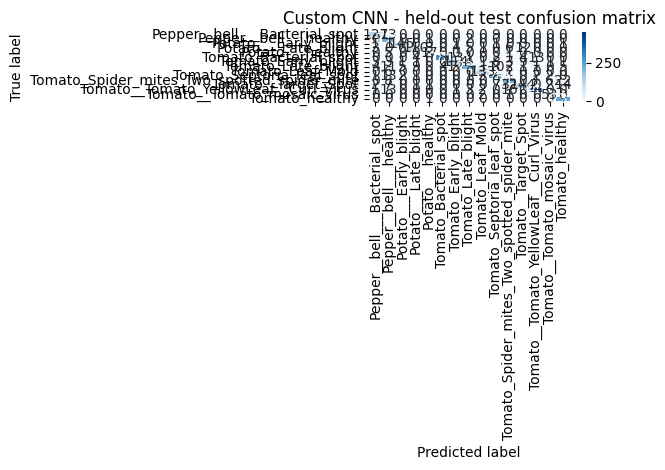

Per-class report:
                                             precision    recall  f1-score  \
Pepper__bell___Bacterial_spot                 0.894366  0.852349  0.872852   
Pepper__bell___healthy                        0.731544  0.986425  0.840077   
Potato___Early_blight                         0.911950  0.966667  0.938511   
Potato___Late_blight                          0.873016  0.733333  0.797101   
Potato___healthy                              0.739130  0.739130  0.739130   
Tomato_Bacterial_spot                         0.985965  0.880878  0.930464   
Tomato_Early_blight                           0.786207  0.760000  0.772881   
Tomato_Late_blight                            0.932773  0.773519  0.845714   
Tomato_Leaf_Mold                              0.930070  0.930070  0.930070   
Tomato_Septoria_leaf_spot                     0.860215  0.902256  0.880734   
Tomato_Spider_mites_Two_spotted_spider_mite   0.767857  0.853175  0.808271   
Tomato__Target_Spot                           

In [14]:
metrics = evaluate_and_save(model, MODEL_NAME, test_ds, y_test, class_names, train_seconds=train_seconds, history=history)
print("Per-class report:")
print(pd.DataFrame(metrics["per_class_report"]).T)


## 7. Interpretation prompts

After execution, record the actual epoch count, test metrics, per-class recall, confusion matrix errors, and whether the learning curves suggest overfitting. Discuss that PlantVillage images are controlled-condition images and do not establish field performance.

## Part 3 - MobileNetV2 transfer learning

Run this section after the baseline. It trains MobileNetV2 using the same discovered classes and split.

# 02 - MobileNetV2 Transfer Learning

MobileNetV2 is a compact ImageNet-pretrained CNN. We freeze its feature extractor, train a new Plant classification head, and provide an optional fine-tuning stage. Using the shared split makes its measured results comparable with the custom CNN.


## 1. Imports, discovery and reproducibility

The setup below discovers only sibling folders whose names identify Plant bacterial spot and healthy leaves. It also creates shared output directories and fixes the random seed. The discovered class order, rather than a hardcoded index, defines the model output mapping.

In [15]:
from pathlib import Path
from collections import Counter
import json, os, random, time
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 64
EPOCHS = 15
print(f"Configured maximum epochs: {EPOCHS}")
CURRENT_DIR = Path.cwd()
PROJECT_DIR = Path("/content/plant_disease_project") if Path("/content/plant_disease_project").exists() else (CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR)
NOTEBOOK_DIR = PROJECT_DIR / "notebooks"
DATA_CANDIDATES = [PROJECT_DIR / "PlantVillage", PROJECT_DIR / "dataset" / "raw", PROJECT_DIR / "dataset"]
MODELS_DIR = PROJECT_DIR / "models"
EVALUATION_DIR = PROJECT_DIR / "evaluation"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".JPG"}

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

def discover_dataset():
    candidates = [p for p in DATA_CANDIDATES if p.exists()]
    candidates += [p for base in DATA_CANDIDATES if base.exists() for p in base.rglob("*") if p.is_dir()]
    matches = []
    for parent in candidates:
        class_dirs = []
        if not parent.is_dir():
            continue
        for child in parent.iterdir():
            if child.is_dir() and any(f.is_file() and f.suffix.lower() in {e.lower() for e in EXTENSIONS} for f in child.iterdir()):
                class_dirs.append(child)
        if len(class_dirs) >= 2:
            matches.append((len(class_dirs), len(parent.parts), parent, sorted(class_dirs, key=lambda p: p.name)))
    if not matches:
        raise FileNotFoundError("Could not find a dataset root with at least two image class folders.")
    _, _, parent, class_dirs = sorted(matches, key=lambda x: (-x[0], x[1], str(x[2])))[0]
    return parent, class_dirs

def collect_records():
    dataset_root, class_dirs = discover_dataset()
    class_names = [p.name for p in class_dirs]
    rows = []
    for label, class_dir in enumerate(class_dirs):
        for path in sorted(class_dir.rglob("*")):
            if path.is_file() and path.suffix.lower() in {e.lower() for e in EXTENSIONS}:
                rows.append({"path": str(path.resolve()), "label": label, "class_name": class_dir.name})
    records = pd.DataFrame(rows)
    if records.empty or len(class_names) < 2:
        raise ValueError("The discovered dataset must contain at least two non-empty classes.")
    return dataset_root, class_names, records

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return tf.cast(image, tf.float32), label

def make_dataset(file_paths, file_labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((np.asarray(file_paths), np.asarray(file_labels, dtype=np.int32)))
    if training:
        ds = ds.shuffle(len(file_paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

def get_or_create_split(records, class_names):
    split_file = EVALUATION_DIR / "split_assignments.json"
    if split_file.exists():
        split = json.loads(split_file.read_text(encoding="utf-8"))
        if split.get("class_names") != class_names:
            raise ValueError("Existing split_assignments.json uses different class names; remove it and recreate the split.")
        return {key: np.asarray(value) for key, value in split["paths"].items()}, {key: np.asarray(value, dtype=np.int32) for key, value in split["labels"].items()}
    paths = records["path"].to_numpy()
    labels = records["label"].to_numpy(dtype=np.int32)
    train_paths, temp_paths, train_labels, temp_labels = train_test_split(paths, labels, test_size=0.30, random_state=SEED, stratify=labels)
    val_paths, test_paths, val_labels, test_labels = train_test_split(temp_paths, temp_labels, test_size=0.50, random_state=SEED, stratify=temp_labels)
    split = {"class_names": class_names, "seed": SEED, "ratios": {"train": 0.70, "validation": 0.15, "test": 0.15}, "paths": {"train": train_paths.tolist(), "validation": val_paths.tolist(), "test": test_paths.tolist()}, "labels": {"train": train_labels.tolist(), "validation": val_labels.tolist(), "test": test_labels.tolist()}}
    split_file.write_text(json.dumps(split, indent=2), encoding="utf-8")
    return {key: np.asarray(value) for key, value in split["paths"].items()}, {key: np.asarray(value, dtype=np.int32) for key, value in split["labels"].items()}

def evaluate_and_save(model, model_name, test_ds, y_test, class_names, train_seconds=None, history=None):
    started = time.perf_counter()
    probabilities = model.predict(test_ds, verbose=1)
    inference_seconds = time.perf_counter() - started
    y_pred = np.argmax(probabilities, axis=1)
    report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True, zero_division=0)
    model_filename = {"Custom CNN": "custom_cnn.keras", "MobileNetV2": "mobilenetv2.keras", "ResNet50": "resnet50.keras"}[model_name]
    model_file = MODELS_DIR / model_filename
    completed_epochs = len(history.get("loss", [])) if isinstance(history, dict) else (len(history.epoch) if history is not None else None)
    metrics = {"model": model_name, "classes": class_names, "test_count": int(len(y_test)), "test_accuracy": float(accuracy_score(y_test, y_pred)), "macro_precision": float(report["macro avg"]["precision"]), "macro_recall": float(report["macro avg"]["recall"]), "macro_f1": float(report["macro avg"]["f1-score"]), "per_class_report": report, "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(), "train_seconds": train_seconds, "inference_seconds": inference_seconds, "model_size_bytes": model_file.stat().st_size if model_file.exists() else None, "epochs": completed_epochs}
    (EVALUATION_DIR / f"{model_name.lower().replace(' ', '_')}_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    print(json.dumps({key: metrics[key] for key in ["model", "test_accuracy", "macro_precision", "macro_recall", "macro_f1", "train_seconds", "inference_seconds"]}, indent=2))
    cm = np.asarray(metrics["confusion_matrix"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted label"); plt.ylabel("True label"); plt.title(f"{model_name} - held-out test confusion matrix"); plt.tight_layout(); plt.show()
    return metrics


Configured maximum epochs: 15


## 2. Build or load the shared stratified split

The first model notebook creates a 70% training, 15% validation and 15% test split. Later notebooks reuse the saved paths exactly. This prevents a model from appearing better simply because it received an easier test set.

In [16]:
dataset_root, class_names, records = collect_records()
paths_by_split, labels_by_split = get_or_create_split(records, class_names)
X_train, X_val, X_test = paths_by_split["train"], paths_by_split["validation"], paths_by_split["test"]
y_train, y_val, y_test = labels_by_split["train"], labels_by_split["validation"], labels_by_split["test"]
NUM_CLASSES = len(class_names)
print("Dataset root:", dataset_root)
print("Classes:", class_names)
print("Split sizes:", {name: len(value) for name, value in paths_by_split.items()})
train_ds, val_ds, test_ds = make_dataset(X_train, y_train, True), make_dataset(X_val, y_val), make_dataset(X_test, y_test)


Dataset root: /content/plant_disease_project/PlantVillage/PlantVillage
Classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Split sizes: {'train': 14446, 'validation': 3096, 'test': 3096}


## 3. Define the model

Images are resized to 224 x 224 and decoded as RGB by `make_dataset`. Augmentation is inside the model, so Keras applies it only while training. The validation and test datasets contain no augmentation.

In [17]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

data_augmentation = tf.keras.Sequential([tf.keras.layers.RandomFlip("horizontal"), tf.keras.layers.RandomRotation(0.08), tf.keras.layers.RandomZoom(0.10)], name="training_augmentation")
base_model = MobileNetV2(input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet")
base_model.trainable = False
inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = tf.keras.layers.Lambda(preprocess_input, name="mobilenet_preprocessing")(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = tf.keras.Model(inputs, outputs, name="mobilenetv2")
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocessing         │ (None, 224, 224, 3)    │             0 │
│ (Lambda)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,277,199 (8.69 MB)

 Trainable params: 19,215 (75.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 4. Train and inspect learning curves

Early stopping restores the weights from the best validation loss. The elapsed time is recorded for the later comparison notebook. A gap between training and validation curves can indicate overfitting.

Epoch 1/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 40s 149ms/step - accuracy: 0.6510 - loss: 1.1234 - val_accuracy: 0.8359 - val_loss: 0.5803 - learning_rate: 0.0010
Epoch 2/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 35s 130ms/step - accuracy: 0.8201 - loss: 0.5673 - val_accuracy: 0.8579 - val_loss: 0.4695 - learning_rate: 0.0010
Epoch 3/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 29s 130ms/step - accuracy: 0.8512 - loss: 0.4727 - val_accuracy: 0.8705 - val_loss: 0.4141 - learning_rate: 0.0010
Epoch 4/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 29s 130ms/step - accuracy: 0.8624 - loss: 0.4275 - val_accuracy: 0.8818 - val_loss: 0.3720 - learning_rate: 0.0010
Epoch 5/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 30s 130ms/step - accuracy: 0.8683 - loss: 0.3913 - val_accuracy: 0.8886 - val_loss: 0.3484 - learning_rate: 0.0010
Epoch 6/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 41s 132ms/step - accuracy: 0.8745 - loss: 0.3769 - val_accuracy: 0.8882 - val_loss: 0.3588 - learning_rate: 0.0010
Epoch 7/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 30s 132ms/step - accuracy: 0.8

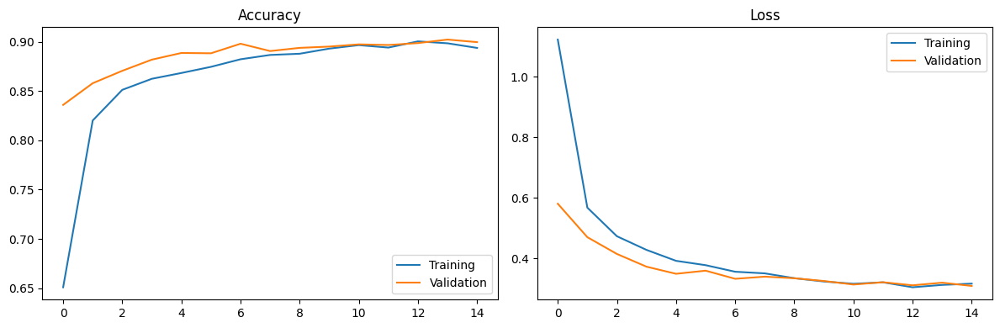

Completed 15 epochs in 516.4 seconds.


In [18]:
callbacks = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True), tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7)]
train_started = time.perf_counter()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)
train_seconds = time.perf_counter() - train_started
history_df = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["accuracy"], label="Training"); axes[0].plot(history_df["val_accuracy"], label="Validation"); axes[0].set_title("Accuracy"); axes[0].legend()
axes[1].plot(history_df["loss"], label="Training"); axes[1].plot(history_df["val_loss"], label="Validation"); axes[1].set_title("Loss"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Completed {len(history.epoch)} epochs in {train_seconds:.1f} seconds.")


## Optional fine-tuning

After the frozen-base training cell completes, you may run the following cell. It unfreezes only the final 30 layers and uses a much smaller learning rate. This is intentionally optional because it increases training time and can overfit a small dataset.

## 5. Save the model and class mapping

The `.keras` file stores the model, including its preprocessing layer. The same discovered class names are saved both beside the models and at project level so the dashboard can map output indices safely.

In [20]:
MODEL_NAME = "MobileNetV2"
model_path = MODELS_DIR / "mobilenetv2.keras"
model.save(model_path)
(PROJECT_DIR / "class_names.json").write_text(json.dumps(class_names, indent=2), encoding="utf-8")
(MODELS_DIR / "class_names.json").write_text(json.dumps(class_names, indent=2), encoding="utf-8")
print("Saved model:", model_path.resolve())


Saved model: /content/plant_disease_project/models/mobilenetv2.keras


## 6. Evaluate once on the independent test set

Accuracy is the overall proportion correct. Macro precision, recall and F1 give each class equal weight, which is useful when class counts differ. The confusion matrix shows which classes are confused. These values are measured from this run; do not copy them into a report before executing the cell.

49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 131ms/step
{
  "model": "MobileNetV2",
  "test_accuracy": 0.914405684754522,
  "macro_precision": 0.9201156746403618,
  "macro_recall": 0.9040627311076118,
  "macro_f1": 0.9101939648813868,
  "train_seconds": 516.3586664669999,
  "inference_seconds": 10.250470665000194
}


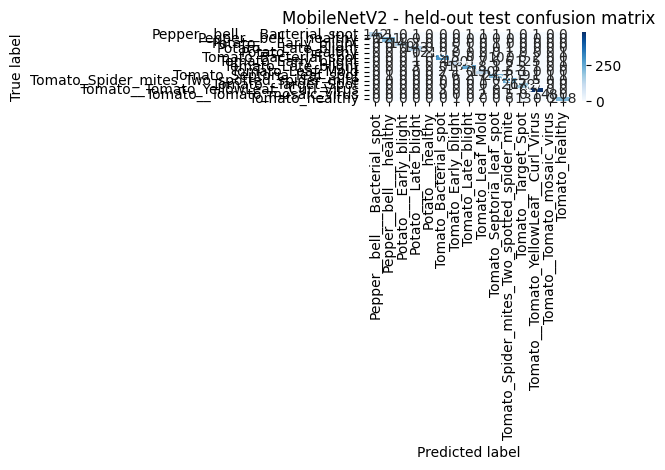

Per-class report:
                                             precision    recall  f1-score  \
Pepper__bell___Bacterial_spot                 1.000000  0.953020  0.975945   
Pepper__bell___healthy                        0.991031  1.000000  0.995495   
Potato___Early_blight                         1.000000  0.973333  0.986486   
Potato___Late_blight                          0.940789  0.953333  0.947020   
Potato___healthy                              1.000000  0.913043  0.954545   
Tomato_Bacterial_spot                         0.948553  0.924765  0.936508   
Tomato_Early_blight                           0.763359  0.666667  0.711744   
Tomato_Late_blight                            0.955390  0.895470  0.924460   
Tomato_Leaf_Mold                              0.828025  0.909091  0.866667   
Tomato_Septoria_leaf_spot                     0.902542  0.800752  0.848606   
Tomato_Spider_mites_Two_spotted_spider_mite   0.795380  0.956349  0.868468   
Tomato__Target_Spot                           

In [21]:
metrics = evaluate_and_save(model, MODEL_NAME, test_ds, y_test, class_names, train_seconds=train_seconds, history=history)
print("Per-class report:")
print(pd.DataFrame(metrics["per_class_report"]).T)


## 7. Interpretation prompts

After execution, record the actual epoch count, test metrics, per-class recall, confusion matrix errors, and whether the learning curves suggest overfitting. Discuss that PlantVillage images are controlled-condition images and do not establish field performance.

## Part 4 - ResNet50 transfer learning

Run this section after MobileNetV2. It trains ResNet50 using the same discovered classes and split.

# 03 - ResNet50 Transfer Learning

ResNet50 is a deeper ImageNet-pretrained CNN that uses residual connections. It may learn stronger visual features, but it requires more memory and computation than MobileNetV2. This notebook follows exactly the same Plant data split and evaluation procedure.


## 1. Imports, discovery and reproducibility

The setup below discovers only sibling folders whose names identify Plant bacterial spot and healthy leaves. It also creates shared output directories and fixes the random seed. The discovered class order, rather than a hardcoded index, defines the model output mapping.

In [23]:
from pathlib import Path
from collections import Counter
import json, os, random, time
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 64
EPOCHS = 10
print(f"Configured maximum epochs: {EPOCHS}")
CURRENT_DIR = Path.cwd()
PROJECT_DIR = Path("/content/plant_disease_project") if Path("/content/plant_disease_project").exists() else (CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR)
NOTEBOOK_DIR = PROJECT_DIR / "notebooks"
DATA_CANDIDATES = [PROJECT_DIR / "PlantVillage", PROJECT_DIR / "dataset" / "raw", PROJECT_DIR / "dataset"]
MODELS_DIR = PROJECT_DIR / "models"
EVALUATION_DIR = PROJECT_DIR / "evaluation"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".JPG"}

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

def discover_dataset():
    candidates = [p for p in DATA_CANDIDATES if p.exists()]
    candidates += [p for base in DATA_CANDIDATES if base.exists() for p in base.rglob("*") if p.is_dir()]
    matches = []
    for parent in candidates:
        class_dirs = []
        if not parent.is_dir():
            continue
        for child in parent.iterdir():
            if child.is_dir() and any(f.is_file() and f.suffix.lower() in {e.lower() for e in EXTENSIONS} for f in child.iterdir()):
                class_dirs.append(child)
        if len(class_dirs) >= 2:
            matches.append((len(class_dirs), len(parent.parts), parent, sorted(class_dirs, key=lambda p: p.name)))
    if not matches:
        raise FileNotFoundError("Could not find a dataset root with at least two image class folders.")
    _, _, parent, class_dirs = sorted(matches, key=lambda x: (-x[0], x[1], str(x[2])))[0]
    return parent, class_dirs

def collect_records():
    dataset_root, class_dirs = discover_dataset()
    class_names = [p.name for p in class_dirs]
    rows = []
    for label, class_dir in enumerate(class_dirs):
        for path in sorted(class_dir.rglob("*")):
            if path.is_file() and path.suffix.lower() in {e.lower() for e in EXTENSIONS}:
                rows.append({"path": str(path.resolve()), "label": label, "class_name": class_dir.name})
    records = pd.DataFrame(rows)
    if records.empty or len(class_names) < 2:
        raise ValueError("The discovered dataset must contain at least two non-empty classes.")
    return dataset_root, class_names, records

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return tf.cast(image, tf.float32), label

def make_dataset(file_paths, file_labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((np.asarray(file_paths), np.asarray(file_labels, dtype=np.int32)))
    if training:
        ds = ds.shuffle(len(file_paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

def get_or_create_split(records, class_names):
    split_file = EVALUATION_DIR / "split_assignments.json"
    if split_file.exists():
        split = json.loads(split_file.read_text(encoding="utf-8"))
        if split.get("class_names") != class_names:
            raise ValueError("Existing split_assignments.json uses different class names; remove it and recreate the split.")
        return {key: np.asarray(value) for key, value in split["paths"].items()}, {key: np.asarray(value, dtype=np.int32) for key, value in split["labels"].items()}
    paths = records["path"].to_numpy()
    labels = records["label"].to_numpy(dtype=np.int32)
    train_paths, temp_paths, train_labels, temp_labels = train_test_split(paths, labels, test_size=0.30, random_state=SEED, stratify=labels)
    val_paths, test_paths, val_labels, test_labels = train_test_split(temp_paths, temp_labels, test_size=0.50, random_state=SEED, stratify=temp_labels)
    split = {"class_names": class_names, "seed": SEED, "ratios": {"train": 0.70, "validation": 0.15, "test": 0.15}, "paths": {"train": train_paths.tolist(), "validation": val_paths.tolist(), "test": test_paths.tolist()}, "labels": {"train": train_labels.tolist(), "validation": val_labels.tolist(), "test": test_labels.tolist()}}
    split_file.write_text(json.dumps(split, indent=2), encoding="utf-8")
    return {key: np.asarray(value) for key, value in split["paths"].items()}, {key: np.asarray(value, dtype=np.int32) for key, value in split["labels"].items()}

def evaluate_and_save(model, model_name, test_ds, y_test, class_names, train_seconds=None, history=None):
    started = time.perf_counter()
    probabilities = model.predict(test_ds, verbose=1)
    inference_seconds = time.perf_counter() - started
    y_pred = np.argmax(probabilities, axis=1)
    report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True, zero_division=0)
    model_filename = {"Custom CNN": "custom_cnn.keras", "MobileNetV2": "mobilenetv2.keras", "ResNet50": "resnet50.keras"}[model_name]
    model_file = MODELS_DIR / model_filename
    completed_epochs = len(history.get("loss", [])) if isinstance(history, dict) else (len(history.epoch) if history is not None else None)
    metrics = {"model": model_name, "classes": class_names, "test_count": int(len(y_test)), "test_accuracy": float(accuracy_score(y_test, y_pred)), "macro_precision": float(report["macro avg"]["precision"]), "macro_recall": float(report["macro avg"]["recall"]), "macro_f1": float(report["macro avg"]["f1-score"]), "per_class_report": report, "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(), "train_seconds": train_seconds, "inference_seconds": inference_seconds, "model_size_bytes": model_file.stat().st_size if model_file.exists() else None, "epochs": completed_epochs}
    (EVALUATION_DIR / f"{model_name.lower().replace(' ', '_')}_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    print(json.dumps({key: metrics[key] for key in ["model", "test_accuracy", "macro_precision", "macro_recall", "macro_f1", "train_seconds", "inference_seconds"]}, indent=2))
    cm = np.asarray(metrics["confusion_matrix"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted label"); plt.ylabel("True label"); plt.title(f"{model_name} - held-out test confusion matrix"); plt.tight_layout(); plt.show()
    return metrics


Configured maximum epochs: 10


## 2. Build or load the shared stratified split

The first model notebook creates a 70% training, 15% validation and 15% test split. Later notebooks reuse the saved paths exactly. This prevents a model from appearing better simply because it received an easier test set.

In [24]:
dataset_root, class_names, records = collect_records()
paths_by_split, labels_by_split = get_or_create_split(records, class_names)
X_train, X_val, X_test = paths_by_split["train"], paths_by_split["validation"], paths_by_split["test"]
y_train, y_val, y_test = labels_by_split["train"], labels_by_split["validation"], labels_by_split["test"]
NUM_CLASSES = len(class_names)
print("Dataset root:", dataset_root)
print("Classes:", class_names)
print("Split sizes:", {name: len(value) for name, value in paths_by_split.items()})
train_ds, val_ds, test_ds = make_dataset(X_train, y_train, True), make_dataset(X_val, y_val), make_dataset(X_test, y_test)


Dataset root: /content/plant_disease_project/PlantVillage/PlantVillage
Classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Split sizes: {'train': 14446, 'validation': 3096, 'test': 3096}


## 3. Define the model

Images are resized to 224 x 224 and decoded as RGB by `make_dataset`. Augmentation is inside the model, so Keras applies it only while training. The validation and test datasets contain no augmentation.

In [25]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

data_augmentation = tf.keras.Sequential([tf.keras.layers.RandomFlip("horizontal"), tf.keras.layers.RandomRotation(0.08), tf.keras.layers.RandomZoom(0.10)], name="training_augmentation")
base_model = ResNet50(input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet")
base_model.trainable = False
inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = tf.keras.layers.Lambda(preprocess_input, name="resnet_preprocessing")(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.4)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = tf.keras.Model(inputs, outputs, name="resnet50")
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocessing (Lambda)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 15)             │        30,735 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,618,447 (90.10 MB)

 Trainable params: 30,735 (120.06 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

## 4. Train and inspect learning curves

Early stopping restores the weights from the best validation loss. The elapsed time is recorded for the later comparison notebook. A gap between training and validation curves can indicate overfitting.

Epoch 1/10
226/226 ━━━━━━━━━━━━━━━━━━━━ 94s 372ms/step - accuracy: 0.7144 - loss: 0.9247 - val_accuracy: 0.8698 - val_loss: 0.4118 - learning_rate: 0.0010
Epoch 2/10
226/226 ━━━━━━━━━━━━━━━━━━━━ 77s 340ms/step - accuracy: 0.8791 - loss: 0.3957 - val_accuracy: 0.9002 - val_loss: 0.3091 - learning_rate: 0.0010
Epoch 3/10
226/226 ━━━━━━━━━━━━━━━━━━━━ 82s 341ms/step - accuracy: 0.9038 - loss: 0.3052 - val_accuracy: 0.9170 - val_loss: 0.2579 - learning_rate: 0.0010
Epoch 4/10
226/226 ━━━━━━━━━━━━━━━━━━━━ 77s 341ms/step - accuracy: 0.9186 - loss: 0.2621 - val_accuracy: 0.9157 - val_loss: 0.2591 - learning_rate: 0.0010
Epoch 5/10
226/226 ━━━━━━━━━━━━━━━━━━━━ 76s 338ms/step - accuracy: 0.9223 - loss: 0.2361 - val_accuracy: 0.9147 - val_loss: 0.2449 - learning_rate: 0.0010
Epoch 6/10
226/226 ━━━━━━━━━━━━━━━━━━━━ 77s 341ms/step - accuracy: 0.9308 - loss: 0.2176 - val_accuracy: 0.9251 - val_loss: 0.2257 - learning_rate: 0.0010
Epoch 7/10
226/226 ━━━━━━━━━━━━━━━━━━━━ 84s 374ms/step - accuracy: 0.9

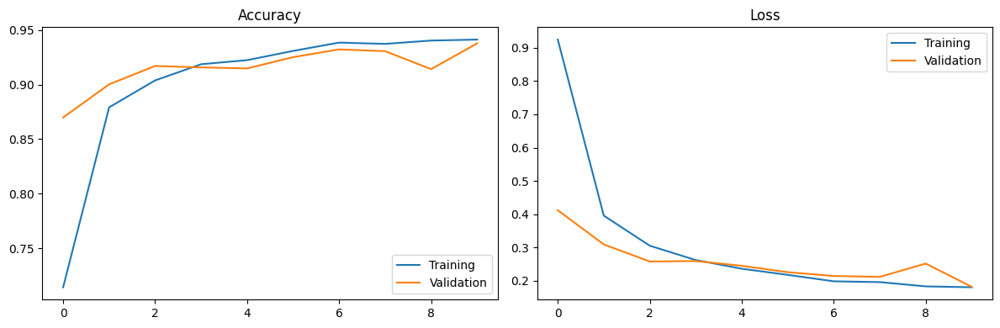

Completed 10 epochs in 803.7 seconds.


In [26]:
callbacks = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True), tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7)]
train_started = time.perf_counter()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)
train_seconds = time.perf_counter() - train_started
history_df = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["accuracy"], label="Training"); axes[0].plot(history_df["val_accuracy"], label="Validation"); axes[0].set_title("Accuracy"); axes[0].legend()
axes[1].plot(history_df["loss"], label="Training"); axes[1].plot(history_df["val_loss"], label="Validation"); axes[1].set_title("Loss"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Completed {len(history.epoch)} epochs in {train_seconds:.1f} seconds.")


## 5. Save the model and class mapping

The `.keras` file stores the model, including its preprocessing layer. The same discovered class names are saved both beside the models and at project level so the dashboard can map output indices safely.

In [27]:
MODEL_NAME = "ResNet50"
model_path = MODELS_DIR / "resnet50.keras"
model.save(model_path)
(PROJECT_DIR / "class_names.json").write_text(json.dumps(class_names, indent=2), encoding="utf-8")
(MODELS_DIR / "class_names.json").write_text(json.dumps(class_names, indent=2), encoding="utf-8")
print("Saved model:", model_path.resolve())


Saved model: /content/plant_disease_project/models/resnet50.keras


## 6. Evaluate once on the independent test set

Accuracy is the overall proportion correct. Macro precision, recall and F1 give each class equal weight, which is useful when class counts differ. The confusion matrix shows which classes are confused. These values are measured from this run; do not copy them into a report before executing the cell.

49/49 ━━━━━━━━━━━━━━━━━━━━ 17s 296ms/step
{
  "model": "ResNet50",
  "test_accuracy": 0.9373385012919897,
  "macro_precision": 0.9389640596473944,
  "macro_recall": 0.9358028623644427,
  "macro_f1": 0.9359461858189593,
  "train_seconds": 803.6642329469998,
  "inference_seconds": 16.914518515000054
}


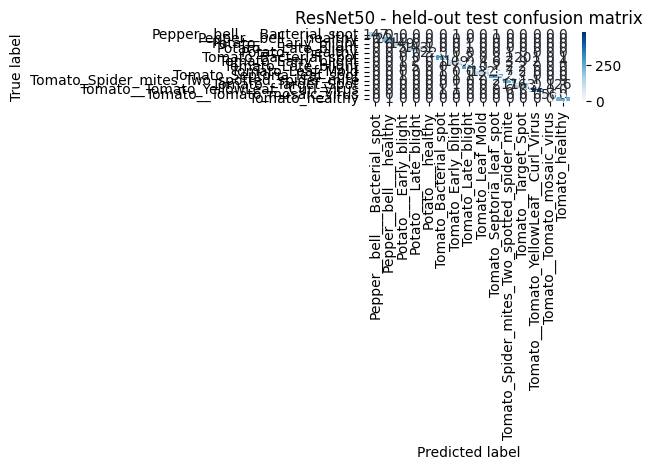

Per-class report:
                                             precision    recall  f1-score  \
Pepper__bell___Bacterial_spot                 1.000000  0.986577  0.993243   
Pepper__bell___healthy                        0.995495  1.000000  0.997743   
Potato___Early_blight                         0.955128  0.993333  0.973856   
Potato___Late_blight                          0.953333  0.953333  0.953333   
Potato___healthy                              0.956522  0.956522  0.956522   
Tomato_Bacterial_spot                         0.989547  0.890282  0.937294   
Tomato_Early_blight                           0.900826  0.726667  0.804428   
Tomato_Late_blight                            0.950530  0.937282  0.943860   
Tomato_Leaf_Mold                              0.956522  0.923077  0.939502   
Tomato_Septoria_leaf_spot                     0.921147  0.966165  0.943119   
Tomato_Spider_mites_Two_spotted_spider_mite   0.856631  0.948413  0.900188   
Tomato__Target_Spot                           

In [28]:
metrics = evaluate_and_save(model, MODEL_NAME, test_ds, y_test, class_names, train_seconds=train_seconds, history=history)
print("Per-class report:")
print(pd.DataFrame(metrics["per_class_report"]).T)


## 7. Interpretation prompts

After execution, record the actual epoch count, test metrics, per-class recall, confusion matrix errors, and whether the learning curves suggest overfitting. Discuss that PlantVillage images are controlled-condition images and do not establish field performance.

## Part 5 - Model comparison

Run this section last. It reads the measured evaluation artifacts and compares the available models.

# 04 - Compare Plant Models

This notebook compares only measured JSON results created by notebooks 01-03. It refuses to invent missing metrics and identifies the best model using the actual macro F1 values, while also showing accuracy, precision, recall, training time, model size and inference time.

## 1. Load available evaluation artifacts

Run the three training notebooks first. A missing model is reported rather than represented by a fabricated zero or sample score.

In [29]:
from pathlib import Path
import os

os.chdir("/content/plant_disease_project")

print("Working directory:", Path.cwd())
print("Evaluation files:", list(Path("evaluation").glob("*.json")))
print("Model files:", list(Path("models").glob("*.keras")))


Working directory: /content/plant_disease_project
Evaluation files: [PosixPath('evaluation/custom_cnn_metrics.json'), PosixPath('evaluation/mobilenetv2_metrics.json'), PosixPath('evaluation/split_assignments.json'), PosixPath('evaluation/resnet50_metrics.json')]
Model files: [PosixPath('models/custom_cnn.keras'), PosixPath('models/resnet50.keras'), PosixPath('models/mobilenetv2.keras')]


In [30]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EVALUATION_DIR = PROJECT_DIR / "evaluation"
expected = {"Custom CNN": EVALUATION_DIR / "custom_cnn_metrics.json", "MobileNetV2": EVALUATION_DIR / "mobilenetv2_metrics.json", "ResNet50": EVALUATION_DIR / "resnet50_metrics.json"}
results = []
for name, path in expected.items():
    if path.exists(): results.append(json.loads(path.read_text(encoding="utf-8")))
    else: print(f"Not available: {name} ({path})")
if not results: raise FileNotFoundError("No model metrics found. Execute notebooks 01-03 first.")
comparison = pd.DataFrame([{**{"Model": r["model"]}, **{key: r.get(key) for key in ["test_accuracy", "macro_precision", "macro_recall", "macro_f1", "train_seconds", "inference_seconds", "model_size_bytes"]}} for r in results]).rename(columns={"test_accuracy":"Accuracy", "macro_precision":"Precision", "macro_recall":"Recall", "macro_f1":"F1"}).sort_values("F1", ascending=False)
display(comparison.style.format({c: "{:.4f}" for c in ["Accuracy", "Precision", "Recall", "F1"]}))


,Model,Accuracy,Precision,Recall,F1,train_seconds,inference_seconds,model_size_bytes
2,ResNet50,0.9373,0.9390,0.9358,0.9359,803.664233,16.914519,95391873
1,MobileNetV2,0.9144,0.9201,0.9041,0.9102,516.358666,10.250471,22098571
0,Custom CNN,0.8727,0.8597,0.8621,0.8570,849.393002,5.122112,4798977


## 2. Compare metrics, cost and model size

Macro F1 is used as the primary ranking metric because it balances precision and recall across both classes. Training time, inference time and model size add deployment context; they do not replace test-set quality.

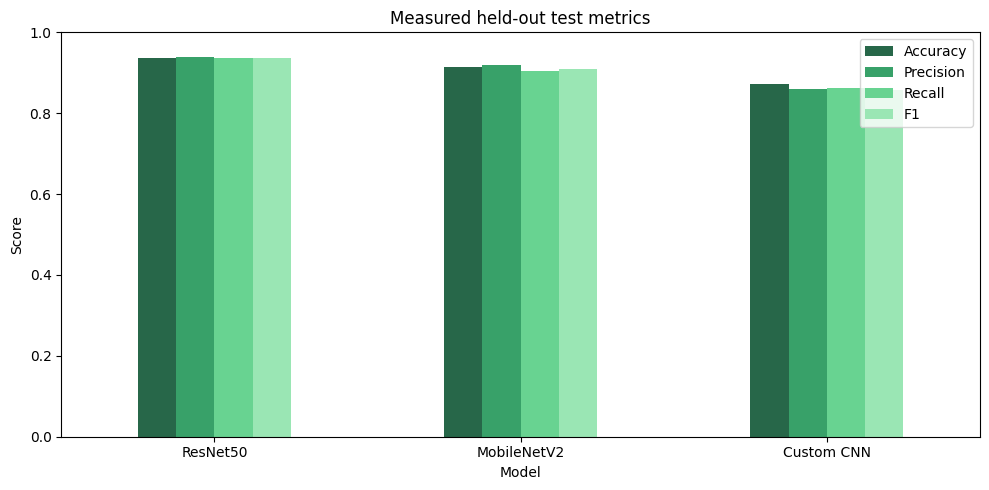

,Model,train_seconds,inference_seconds,model_size_bytes
2,ResNet50,803.664233,16.914519,95391873
1,MobileNetV2,516.358666,10.250471,22098571
0,Custom CNN,849.393002,5.122112,4798977


Best by measured macro F1: ResNet50 (0.9359)


909

In [31]:
ax = comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0, color=["#276749", "#38a169", "#68d391", "#9ae6b4"])
ax.set_ylabel("Score"); ax.set_title("Measured held-out test metrics"); plt.tight_layout(); plt.show()
display(comparison[["Model", "train_seconds", "inference_seconds", "model_size_bytes"]])
best = comparison.iloc[0]
print(f"Best by measured macro F1: {best.Model} ({best.F1:.4f})")
(EVALUATION_DIR / "model_comparison.json").write_text(json.dumps({"ranking_metric":"macro_f1", "best_model": str(best.Model), "results": json.loads(comparison.to_json(orient="records"))}, indent=2), encoding="utf-8")


## 3. Confusion matrices and classification reports

A confusion matrix reveals whether the model misses bacterial spot or healthy leaves. The full classification reports retain per-class precision, recall and F1 for academic interpretation.

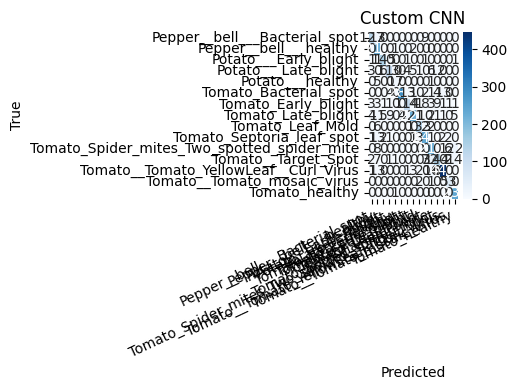

,precision,recall,f1-score,support
Pepper__bell___Bacterial_spot,0.894366,0.852349,0.872852,149.000000
Pepper__bell___healthy,0.731544,0.986425,0.840077,221.000000
Potato___Early_blight,0.911950,0.966667,0.938511,150.000000
Potato___Late_blight,0.873016,0.733333,0.797101,150.000000
Potato___healthy,0.739130,0.739130,0.739130,23.000000
Tomato_Bacterial_spot,0.985965,0.880878,0.930464,319.000000
Tomato_Early_blight,0.786207,0.760000,0.772881,150.000000
Tomato_Late_blight,0.932773,0.773519,0.845714,287.000000
Tomato_Leaf_Mold,0.930070,0.930070,0.930070,143.000000
Tomato_Septoria_leaf_spot,0.860215,0.902256,0.880734,266.000000


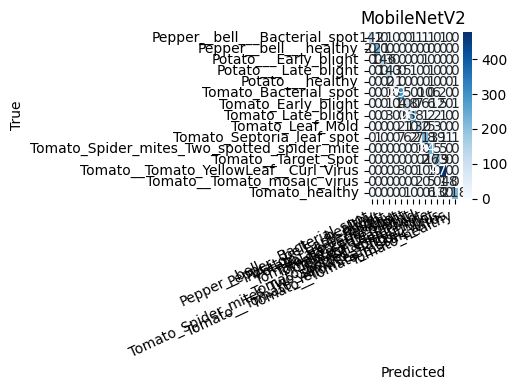

,precision,recall,f1-score,support
Pepper__bell___Bacterial_spot,1.000000,0.953020,0.975945,149.000000
Pepper__bell___healthy,0.991031,1.000000,0.995495,221.000000
Potato___Early_blight,1.000000,0.973333,0.986486,150.000000
Potato___Late_blight,0.940789,0.953333,0.947020,150.000000
Potato___healthy,1.000000,0.913043,0.954545,23.000000
Tomato_Bacterial_spot,0.948553,0.924765,0.936508,319.000000
Tomato_Early_blight,0.763359,0.666667,0.711744,150.000000
Tomato_Late_blight,0.955390,0.895470,0.924460,287.000000
Tomato_Leaf_Mold,0.828025,0.909091,0.866667,143.000000
Tomato_Septoria_leaf_spot,0.902542,0.800752,0.848606,266.000000


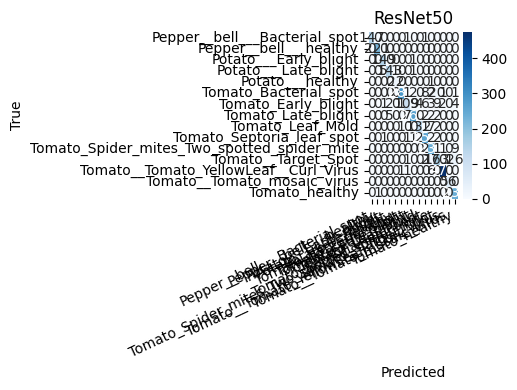

,precision,recall,f1-score,support
Pepper__bell___Bacterial_spot,1.000000,0.986577,0.993243,149.000000
Pepper__bell___healthy,0.995495,1.000000,0.997743,221.000000
Potato___Early_blight,0.955128,0.993333,0.973856,150.000000
Potato___Late_blight,0.953333,0.953333,0.953333,150.000000
Potato___healthy,0.956522,0.956522,0.956522,23.000000
Tomato_Bacterial_spot,0.989547,0.890282,0.937294,319.000000
Tomato_Early_blight,0.900826,0.726667,0.804428,150.000000
Tomato_Late_blight,0.950530,0.937282,0.943860,287.000000
Tomato_Leaf_Mold,0.956522,0.923077,0.939502,143.000000
Tomato_Septoria_leaf_spot,0.921147,0.966165,0.943119,266.000000


In [32]:
for result in results:
    labels = result["classes"]; matrix = np.asarray(result["confusion_matrix"])
    fig, ax = plt.subplots(figsize=(5, 4)); sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(result["model"]); ax.set_xlabel("Predicted"); ax.set_ylabel("True"); plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()
    display(pd.DataFrame(result["per_class_report"]).T)


In [33]:
%cd /content/plant_disease_project

!zip -r /content/dashboard_artifacts.zip models evaluation class_names.json

from google.colab import files
files.download("/content/dashboard_artifacts.zip")


/content
  adding: models/ (stored 0%)
  adding: models/custom_cnn.keras (deflated 8%)
  adding: models/resnet50.keras (deflated 8%)
  adding: models/class_names.json (deflated 60%)
  adding: models/mobilenetv2.keras (deflated 10%)
  adding: evaluation/ (stored 0%)
  adding: evaluation/custom_cnn_metrics.json (deflated 79%)
  adding: evaluation/mobilenetv2_metrics.json (deflated 79%)
  adding: evaluation/split_assignments.json (deflated 80%)
  adding: evaluation/model_comparison.json (deflated 61%)
  adding: evaluation/resnet50_metrics.json (deflated 80%)
  adding: class_names.json (deflated 60%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4. Interpretation

Use the saved ranking and plots to justify a model. Discuss trade-offs if the highest F1 model is slower or larger. Do not generalize PlantVillage test performance to field conditions without an additional field dataset.